In [1]:
from pathlib import Path
import json

DATA_DIR = Path(
    r"E:\clarity_cpc2\data\extracted\clarity_CPC2_data\clarity_data"
)

# Load the listening-test examples for CEC2 training partition 1.
metadata_path = DATA_DIR / "metadata" / "CEC2.train.1.json"

with metadata_path.open(encoding="utf-8") as file:
    examples = json.load(file)

audio_dir = DATA_DIR / "HA_outputs" / "signals" / "CEC2"

# Several listening tests may use the same audio file.
required_files = {
    str(example["signal"]).removesuffix(".wav") + ".wav"
    for example in examples
}

missing_files = sorted(
    filename
    for filename in required_files
    if not (audio_dir / filename).is_file()
)

print("Listening-test examples:", len(examples))
print("Unique audio files required:", len(required_files))
print("Required audio files found:", len(required_files) - len(missing_files))
print("Missing audio files:", len(missing_files))

if missing_files:
    print("\nFirst five missing filenames:")
    for filename in missing_files[:5]:
        print(filename)

Listening-test examples: 2779
Unique audio files required: 2779
Required audio files found: 2779
Missing audio files: 0


In [2]:
import sys
print(sys.version)
print(sys.executable)

3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]
c:\Users\tefer\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [3]:
%pip install --timeout 120 pandas numpy matplotlib scikit-learn soundfile ipykernel

  Using cached soundfile-0.14.0-py2.py3-none-win_amd64.whl.metadata (18 kB)
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   -------------------- ------------------- 0.5/1.0 MB 5.1 MB/s eta 0:00:01
   ---------------------------------------- 1.0/1.0 MB 5.5 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import soundfile as sf

PROJECT_DIR = Path(r"E:\clarity_cpc2")
DATA_DIR = PROJECT_DIR / "data/extracted/clarity_CPC2_data/clarity_data"
AUDIO_DIR = DATA_DIR / "HA_outputs/signals/CEC2"

# Load the listening-test results.
with (DATA_DIR / "metadata/CEC2.train.1.json").open(encoding="utf-8") as file:
    responses = pd.DataFrame(json.load(file))

# Load the listeners' hearing measurements.
with (DATA_DIR / "metadata/listeners.json").open(encoding="utf-8") as file:
    listeners = json.load(file)

print("Listening-test examples:", len(responses))
print("Listeners in this partition:", responses["listener"].nunique())
print("Audio folder exists:", AUDIO_DIR.is_dir())

display(responses.head())

Listening-test examples: 2779
Listeners in this partition: 10
Audio folder exists: True


,prompt,scene,n_words,hits,listener,system,response,volume,signal,correctness
0,i could feel its presence and now i can't,S08792,9,5,L0200,E008_hr,i could feel and now,96,S08792_L0200_E008_hr,55.555556
1,the engineer would go to sleep soon in a corner,S09161,10,2,L0200,E008_hr,their engineer was in at,96,S09161_L0200_E008_hr,20.000000
2,and to ask you to support dad,S09377,7,1,L0200,E008_hr,to cook over,96,S09377_L0200_E008_hr,14.285714
3,i was about to telephone the police,S08892,7,2,L0200,E008_hr,to telephone,96,S08892_L0200_E008_hr,28.571429
4,finally he put it in his mouth,S09432,7,0,L0200,E008_hr,,96,S09432_L0200_E008_hr,0.000000


In [ ]:
# LOading the data from collab

LOADING THE CELLS FROM THE PROVIOUS COLLAB WORK, I AM DOING THIS HERE ON MY LOCAL COMPUTER SO THAT IT IS EASIER TO LOAD UP DATA RATHER THAN DEPENDING ON THE /CONTETNS THAT I HAD BEEN USING FOR THE COLLAB.


In [5]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf

from IPython.display import Audio, display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

PROJECT_DIR = Path(r"E:\clarity_cpc2")
DATA_DIR = (
    PROJECT_DIR
    / "data"
    / "extracted"
    / "clarity_CPC2_data"
    / "clarity_data"
)
METADATA_DIR = DATA_DIR / "metadata"
AUDIO_DIR = DATA_DIR / "HA_outputs" / "signals" / "CEC2"

assert METADATA_DIR.is_dir(), f"Metadata folder missing: {METADATA_DIR}"
assert AUDIO_DIR.is_dir(), f"Audio folder missing: {AUDIO_DIR}"

print("Python:", sys.version.split()[0])
print("Project:", PROJECT_DIR)
print("Data folders found.")

Python: 3.14.3
Project: E:\clarity_cpc2
Data folders found.


In [6]:
with (METADATA_DIR / "CEC2.train.1.json").open(encoding="utf-8") as file:
    responses = pd.DataFrame(json.load(file))

with (METADATA_DIR / "listeners.json").open(encoding="utf-8") as file:
    listeners = json.load(file)

print("Listening-test examples:", len(responses))
print("Unique listeners in this partition:", responses["listener"].nunique())
print("\nColumns:", responses.columns.tolist())

display(responses.head())

Listening-test examples: 2779
Unique listeners in this partition: 10

Columns: ['prompt', 'scene', 'n_words', 'hits', 'listener', 'system', 'response', 'volume', 'signal', 'correctness']


,prompt,scene,n_words,hits,listener,system,response,volume,signal,correctness
0,i could feel its presence and now i can't,S08792,9,5,L0200,E008_hr,i could feel and now,96,S08792_L0200_E008_hr,55.555556
1,the engineer would go to sleep soon in a corner,S09161,10,2,L0200,E008_hr,their engineer was in at,96,S09161_L0200_E008_hr,20.000000
2,and to ask you to support dad,S09377,7,1,L0200,E008_hr,to cook over,96,S09377_L0200_E008_hr,14.285714
3,i was about to telephone the police,S08892,7,2,L0200,E008_hr,to telephone,96,S08892_L0200_E008_hr,28.571429
4,finally he put it in his mouth,S09432,7,0,L0200,E008_hr,,96,S09432_L0200_E008_hr,0.000000


In [7]:
def get_audio_path(signal):
    filename = str(signal)
    if not filename.endswith(".wav"):
        filename += ".wav"
    return AUDIO_DIR / filename


required_signals = responses["signal"].unique()

missing_signals = [
    signal
    for signal in required_signals
    if not get_audio_path(signal).is_file()
]

print("Unique audio files required:", len(required_signals))
print("Audio files found:", len(required_signals) - len(missing_signals))
print("Missing audio files:", len(missing_signals))

if missing_signals:
    print("First five missing:", missing_signals[:5])

Unique audio files required: 2779
Audio files found: 2779
Missing audio files: 0


In [8]:
# Use the example we explored previously if it is present.
previous_signal = "S08792_L0200_E008_hr"

matches = responses[
    responses["signal"].astype(str).str.removesuffix(".wav")
    == previous_signal
]

example = matches.iloc[0] if not matches.empty else responses.iloc[0]

listener_id = example["listener"]
listener_info = listeners[listener_id]

print("Listener:", listener_id)
print("Original sentence:", example["prompt"])
print("Listener's response:", example["response"])
print(f"Words understood: {example['correctness']:.1f}%")

audiogram = pd.DataFrame({
    "Frequency (Hz)": listener_info["audiogram_cfs"],
    "Left ear (dB HL)": listener_info["audiogram_levels_l"],
    "Right ear (dB HL)": listener_info["audiogram_levels_r"],
})

display(audiogram)

Listener: L0200
Original sentence: i could feel its presence and now i can't
Listener's response: i could feel and now
Words understood: 55.6%


,Frequency (Hz),Left ear (dB HL),Right ear (dB HL)
0,250,35,45
1,500,30,45
2,1000,25,20
3,2000,50,50
4,3000,55,70
5,4000,65,65
6,6000,70,80
7,8000,65,75


In [9]:
frequencies = [250, 500, 1000, 2000, 3000, 4000, 6000, 8000]
hearing_rows = []

# Only build features for listeners in our selected partition.
for listener_id in responses["listener"].unique():
    info = listeners[listener_id]

    left = dict(zip(
        info["audiogram_cfs"],
        info["audiogram_levels_l"],
    ))
    right = dict(zip(
        info["audiogram_cfs"],
        info["audiogram_levels_r"],
    ))

    row = {"listener": listener_id}

    for frequency in frequencies:
        row[f"left_{frequency}_Hz"] = left.get(frequency, np.nan)
        row[f"right_{frequency}_Hz"] = right.get(frequency, np.nan)

    hearing_rows.append(row)

hearing_features = pd.DataFrame(hearing_rows)

data = responses.merge(
    hearing_features,
    on="listener",
    how="left",
    validate="many_to_one",
)

feature_columns = [
    f"{ear}_{frequency}_Hz"
    for frequency in frequencies
    for ear in ["left", "right"]
]

# Inputs: hearing measurements only.
X = data[feature_columns].astype(float)

# Target: percentage of words understood.
y = pd.to_numeric(data["correctness"], errors="raise")

assert not X.isna().any().any(), "Some hearing measurements are missing."
assert not y.isna().any(), "Some understanding scores are missing."
assert y.between(0, 100).all(), "Expected scores between 0 and 100."

print("Number of listening-test examples:", len(data))
print("Number of hearing features:", X.shape[1])
print("Missing hearing measurements:", int(X.isna().sum().sum()))

display(data[["listener", "correctness"] + feature_columns].head())

Number of listening-test examples: 2779
Number of hearing features: 16
Missing hearing measurements: 0


,listener,correctness,left_250_Hz,right_250_Hz,left_500_Hz,right_500_Hz,left_1000_Hz,right_1000_Hz,left_2000_Hz,right_2000_Hz,left_3000_Hz,right_3000_Hz,left_4000_Hz,right_4000_Hz,left_6000_Hz,right_6000_Hz,left_8000_Hz,right_8000_Hz
0,L0200,55.555556,35,45,30,45,25,20,50,50,55,70,65,65,70,80,65,75
1,L0200,20.000000,35,45,30,45,25,20,50,50,55,70,65,65,70,80,65,75
2,L0200,14.285714,35,45,30,45,25,20,50,50,55,70,65,65,70,80,65,75
3,L0200,28.571429,35,45,30,45,25,20,50,50,55,70,65,65,70,80,65,75
4,L0200,0.000000,35,45,30,45,25,20,50,50,55,70,65,65,70,80,65,75


In [10]:
# Keep each listener entirely in training or validation.
# This is our exploratory split within CEC2 training partition 1.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

train_indices, val_indices = next(
    splitter.split(X, y, groups=data["listener"])
)

X_train = X.iloc[train_indices].copy()
X_val = X.iloc[val_indices].copy()

y_train = y.iloc[train_indices].copy()
y_val = y.iloc[val_indices].copy()

train_listeners = set(data.iloc[train_indices]["listener"])
val_listeners = set(data.iloc[val_indices]["listener"])

assert train_listeners.isdisjoint(val_listeners)

print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Training listeners:", len(train_listeners))
print("Validation listeners:", len(val_listeners))
print("Shared listeners:", len(train_listeners & val_listeners))

Training examples: 2221
Validation examples: 558
Training listeners: 8
Validation listeners: 2
Shared listeners: 0


In [11]:
def rmse(actual, predicted):
    return float(np.sqrt(mean_squared_error(actual, predicted)))


# Learn the constant from training labels only.
constant_prediction = y_train.mean()

baseline_val_predictions = np.full(
    shape=len(y_val),
    fill_value=constant_prediction,
)

baseline_val_rmse = rmse(y_val, baseline_val_predictions)

print(f"Constant prediction: {constant_prediction:.1f}% understood")
print(
    f"Baseline validation RMSE: "
    f"{baseline_val_rmse:.2f} percentage points"
)

Constant prediction: 54.1% understood
Baseline validation RMSE: 39.90 percentage points


In [12]:
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    random_state=42,
    n_jobs=-1,
)

model.fit(X_train, y_train)

train_predictions = model.predict(X_train)
val_predictions = model.predict(X_val)

train_rmse = rmse(y_train, train_predictions)
val_rmse = rmse(y_val, val_predictions)

print(f"Training RMSE: {train_rmse:.2f} percentage points")
print(f"Validation RMSE: {val_rmse:.2f} percentage points")
print(
    f"Baseline validation RMSE: "
    f"{baseline_val_rmse:.2f} percentage points"
)

results = pd.DataFrame({
    "Model": ["Constant baseline", "Audiogram random forest"],
    "Training RMSE": [
        rmse(y_train, np.full(len(y_train), constant_prediction)),
        train_rmse,
    ],
    "Validation RMSE": [baseline_val_rmse, val_rmse],
})

display(results.round(2))

Training RMSE: 39.46 percentage points
Validation RMSE: 39.79 percentage points
Baseline validation RMSE: 39.90 percentage points


,Model,Training RMSE,Validation RMSE
0,Constant baseline,39.81,39.90
1,Audiogram random forest,39.46,39.79


In [13]:
audio_path = get_audio_path(example["signal"])

assert audio_path.is_file(), f"Audio file missing: {audio_path}"

# Always use shape (samples, channels), even for mono audio.
audio, sample_rate = sf.read(audio_path, always_2d=True)
duration = len(audio) / sample_rate

print("Audio file:", audio_path.name)
print("Sample rate:", sample_rate, "Hz")
print("Channels:", audio.shape[1])
print(f"Duration: {duration:.2f} seconds")

print("\nOriginal sentence:", example["prompt"])
print("Listener's response:", example["response"])
print(f"Actual understanding: {example['correctness']:.1f}%")

# Notebook playback expects shape (channels, samples).
# Playback is for exploration, not calibrated hearing assessment.
display(Audio(audio.T, rate=sample_rate))


Audio file: S08792_L0200_E008_hr.wav
Sample rate: 32000 Hz
Channels: 2
Duration: 5.97 seconds

Original sentence: i could feel its presence and now i can't
Listener's response: i could feel and now
Actual understanding: 55.6%


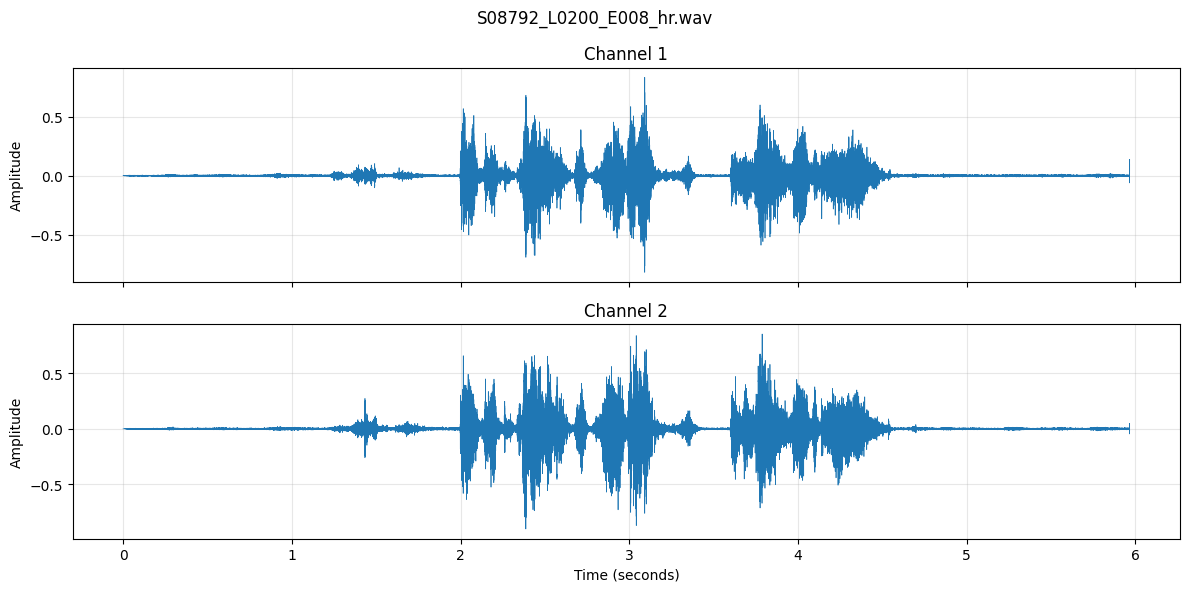

In [14]:
time_seconds = np.arange(len(audio)) / sample_rate
number_of_channels = audio.shape[1]

fig, axes = plt.subplots(
    number_of_channels,
    1,
    figsize=(12, 3 * number_of_channels),
    sharex=True,
    squeeze=False,
)

for channel in range(number_of_channels):
    ax = axes[channel, 0]

    ax.plot(time_seconds, audio[:, channel], linewidth=0.5)
    ax.set_title(f"Channel {channel + 1}")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)

axes[-1, 0].set_xlabel("Time (seconds)")
fig.suptitle(audio_path.name)
plt.tight_layout()
plt.show()

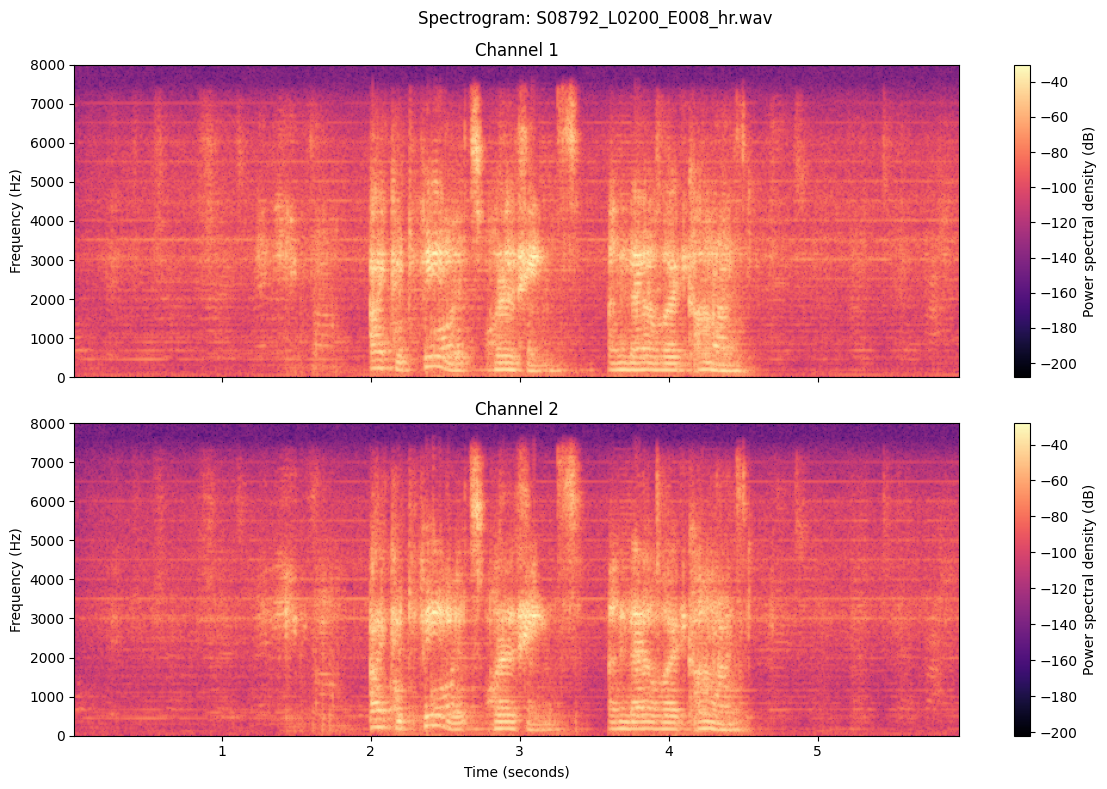

In [15]:
# Uses audio and sample_rate from the previous cells.

fig, axes = plt.subplots(
    audio.shape[1],
    1,
    figsize=(12, 4 * audio.shape[1]),
    sharex=True,
    squeeze=False,
)

for channel in range(audio.shape[1]):
    ax = axes[channel, 0]

    spectrum, frequencies, times, image = ax.specgram(
        audio[:, channel],
        NFFT=1024,
        Fs=sample_rate,
        noverlap=768,
        cmap="magma",
        scale="dB",
    )

    ax.set_title(f"Channel {channel + 1}")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(0, min(8000, sample_rate / 2))

    fig.colorbar(image, ax=ax, label="Power spectral density (dB)")

axes[-1, 0].set_xlabel("Time (seconds)")
fig.suptitle(f"Spectrogram: {audio_path.name}")
plt.tight_layout()
plt.show()

In [16]:
display(Audio(audio.T, rate=sample_rate))

In [17]:
from scipy.signal import welch

def extract_audio_features(audio_path):
    audio, sample_rate = sf.read(
        audio_path,
        dtype="float32",
        always_2d=True,
    )

    if len(audio) < 2 or not np.isfinite(audio).all():
        raise ValueError(f"Invalid audio: {audio_path}")

    # Calculate features per channel, then average across channels.
    # This avoids cancelling signals by mixing the ears together.
    rms_per_channel = np.sqrt(
        np.mean(audio.astype(np.float64) ** 2, axis=0)
    )

    peak_per_channel = np.max(np.abs(audio), axis=0)

    zero_crossing_per_channel = np.mean(
        np.signbit(audio[1:]) != np.signbit(audio[:-1]),
        axis=0,
    )

    # Estimate how power is distributed across frequencies.
    frequencies, power = welch(
        audio,
        fs=sample_rate,
        nperseg=min(1024, len(audio)),
        axis=0,
    )

    average_power = power.mean(axis=1)
    total_power = average_power.sum()

    if total_power > 0:
        spectral_centroid = (
            frequencies * average_power
        ).sum() / total_power

        high_frequency_ratio = (
            average_power[frequencies >= 4000].sum() / total_power
        )
    else:
        spectral_centroid = 0.0
        high_frequency_ratio = 0.0

    return {
        "duration_seconds": len(audio) / sample_rate,
        "rms": rms_per_channel.mean(),
        "peak_amplitude": peak_per_channel.mean(),
        "crest_factor": np.mean(
            peak_per_channel / np.maximum(rms_per_channel, 1e-12)
        ),
        "zero_crossing_rate": zero_crossing_per_channel.mean(),
        "spectral_centroid_hz": spectral_centroid,
        "high_frequency_ratio": high_frequency_ratio,
    }

In [18]:
example_features = extract_audio_features(
    get_audio_path(example["signal"])
)

display(
    pd.Series(example_features, name="Feature value").to_frame()
)

,Feature value
duration_seconds,5.966000
rms,0.072601
peak_amplitude,0.868927
crest_factor,12.038817
zero_crossing_rate,0.176027
spectral_centroid_hz,2211.676861
high_frequency_ratio,0.029428


In [19]:
signals = data["signal"].unique()
feature_rows = []

for number, signal in enumerate(signals, start=1):
    features = extract_audio_features(get_audio_path(signal))
    features["signal"] = signal
    feature_rows.append(features)

    if number % 100 == 0 or number == len(signals):
        print(f"Processed {number:,}/{len(signals):,} audio files")

audio_features = pd.DataFrame(feature_rows)

# Save the small feature table so we can reuse it later.
FEATURE_DIR = PROJECT_DIR / "features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

feature_path = FEATURE_DIR / "audio_features_v1.csv"
audio_features.to_csv(feature_path, index=False)

print("\nSaved:", feature_path)
display(audio_features.head())

Processed 100/2,779 audio files
Processed 200/2,779 audio files
Processed 300/2,779 audio files
Processed 400/2,779 audio files
Processed 500/2,779 audio files
Processed 600/2,779 audio files
Processed 700/2,779 audio files
Processed 800/2,779 audio files
Processed 900/2,779 audio files
Processed 1,000/2,779 audio files
Processed 1,100/2,779 audio files
Processed 1,200/2,779 audio files
Processed 1,300/2,779 audio files
Processed 1,400/2,779 audio files
Processed 1,500/2,779 audio files
Processed 1,600/2,779 audio files
Processed 1,700/2,779 audio files
Processed 1,800/2,779 audio files
Processed 1,900/2,779 audio files
Processed 2,000/2,779 audio files
Processed 2,100/2,779 audio files
Processed 2,200/2,779 audio files
Processed 2,300/2,779 audio files
Processed 2,400/2,779 audio files
Processed 2,500/2,779 audio files
Processed 2,600/2,779 audio files
Processed 2,700/2,779 audio files
Processed 2,779/2,779 audio files

Saved: E:\clarity_cpc2\features\audio_features_v1.csv


,duration_seconds,rms,peak_amplitude,crest_factor,zero_crossing_rate,spectral_centroid_hz,high_frequency_ratio,signal
0,5.966,0.072601,0.868927,12.038817,0.176027,2211.676861,0.029428,S08792_L0200_E008_hr
1,6.450,0.060047,0.808563,13.582110,0.167775,1951.571767,0.070033,S09161_L0200_E008_hr
2,5.106,0.058485,0.634125,10.867578,0.186828,1374.638490,0.070758,S09377_L0200_E008_hr
3,5.338,0.064827,0.758911,11.748715,0.168381,1851.336825,0.116457,S08892_L0200_E008_hr
4,5.194,0.057475,0.649368,11.385015,0.101337,1262.840862,0.078255,S09432_L0200_E008_hr
